In [1]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Personnal
from libraries.data_loader import load_datas

# 1. Load datas

## 1.1. MNIST test

In [2]:
path = r"datas/brut/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_TRAIN, Y_TRAIN, X_VAL, Y_VAL = load_datas(path, keys)


X_TRAIN = X_TRAIN.reshape((60000, 1, 28, 28))
X_VAL = X_VAL[:].reshape((10000, 1, 28, 28))


X_TRAIN.shape, X_VAL.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

## 1.2. Latent test + MorphoMNIST test ($z_{act, mix}$, $y_{disc}$)

In [216]:
latent_test_path = r"datas\brut\z_act_mix.csv"

nmods = 5
Morpho_test_path = f"datas\\MorphoMNIST\\{nmods}_10\\Y_disc.csv"

z_act_mix = pd.read_csv(latent_test_path)
y_disc = pd.read_csv(Morpho_test_path)

z_act_mix.head(10)

,24,36,3,25,21,33,26,43,38,40,...,22,4,10,41,20,31,27,19,14,39
0,-0.167848,0.877249,-2.419570,-0.821540,0.789623,0.537393,0.979894,0.630535,0.551719,1.271499,...,0.244937,-0.033302,0.021839,-0.334690,0.058168,0.147661,-0.285290,-0.241294,0.127128,-0.116712
1,-0.513359,-0.561446,1.305558,0.293582,-2.970291,-0.154321,-1.064934,-1.315598,-0.329532,-1.087535,...,-0.677390,-1.133839,-1.025260,0.566719,-0.811193,-0.740626,-0.581199,1.065670,0.218937,0.029720
2,-2.200929,-1.119576,0.200688,0.095202,0.164410,0.877677,0.397622,0.133279,-0.303290,-0.124841,...,-0.274826,0.031830,0.010194,0.020773,-0.039979,0.053413,-0.141140,0.106036,0.122870,-0.167953
3,0.953803,0.197884,-0.237537,1.019155,0.019350,-1.470674,1.474770,-0.500433,0.176988,-0.928749,...,0.311281,-0.187279,-0.115489,0.540916,0.425460,0.183578,0.429480,0.284673,-0.151406,0.155518
4,0.460676,1.400474,0.658669,0.622022,0.281464,1.199245,-0.799182,1.182759,-0.856209,0.798141,...,0.753601,0.440321,-0.275433,0.029788,-0.386370,-0.282071,-0.483767,-0.089588,-0.809915,-0.322145
5,-1.903926,-0.939766,-0.590925,-1.052722,0.290857,-0.569220,-0.454050,-0.008835,0.072239,0.352499,...,0.027781,0.188780,0.111723,-0.037432,-0.045751,-0.115433,-0.199412,0.117089,0.142462,-0.023250
6,-0.096399,0.975192,-0.742948,-0.255425,0.263320,0.880352,-0.630242,1.721723,-2.013090,2.173570,...,0.364553,0.707455,-0.728023,-1.262649,-0.219607,0.147903,-0.104514,0.353953,-0.152614,-0.326661
7,-0.618280,1.596765,1.054169,0.986456,-0.838148,-0.380093,-0.701295,-1.903361,2.119350,-0.522549,...,1.217586,2.344271,0.194183,-1.265606,-0.418623,-0.353051,-1.103503,1.186802,0.106893,-0.502847
8,0.788370,0.470140,0.764432,-0.201692,0.420812,0.608177,-3.002104,0.407895,-2.589269,0.214524,...,-1.524186,-1.220769,-0.211687,0.695181,0.645481,2.252166,-1.774130,-0.849138,0.441953,-0.077049
9,0.476258,0.164500,-1.270725,-0.034719,1.912026,-0.785679,0.187978,0.292709,1.011292,-0.376141,...,-0.828566,0.411643,-0.094580,0.714031,-0.010164,0.057747,0.259842,-0.665214,-0.044170,0.006226


## 1.3. Latent + MorphoMNIST BN sample ($\tilde{z}_{act,mix}$, $\tilde{y}_{disc}$)

In [217]:
arcs_percent = 99
path = f'datas\\MorphoMNIST\\{nmods}_10\\rbn_{arcs_percent}'
latent_Morpho_BN_path = f"\\boot_10k-rbn_{arcs_percent}.csv"
latent_Morpho_BN = pd.read_csv(path +latent_Morpho_BN_path, index_col=0)
latent_Morpho_BN.index = np.arange(latent_Morpho_BN.shape[0])

tilde_z_act_mix = latent_Morpho_BN.iloc[:, :z_act_mix.shape[1]]
tilde_z_act_mix.columns = [int(col.split("_")[-1]) for col in z_act_mix.columns]
tilde_y_disc = latent_Morpho_BN.iloc[:, z_act_mix.shape[1]:]
del latent_Morpho_BN

tilde_z_act_mix.head(10)

,24,36,3,25,21,33,26,43,38,40,...,22,4,10,41,20,31,27,19,14,39
0,0.482972,-0.327799,0.425798,-0.877405,-0.548314,-1.505907,-0.848074,0.984892,0.395370,-1.329088,...,-0.101398,-1.709181,0.487569,0.154229,-0.351309,-0.663375,0.491049,-0.667723,-0.721852,0.504276
1,0.514914,-0.807184,2.083411,1.026903,-0.263838,-1.134923,1.435930,-0.424665,-0.200890,0.719228,...,-0.087179,-0.874793,0.690619,-0.676407,-0.127194,-0.449583,-0.224323,-0.227992,-0.114241,-0.276047
2,-0.076229,1.581054,0.056352,-0.930192,0.815907,0.195114,-0.347176,-0.939898,1.945691,0.103572,...,1.780097,-0.964401,0.066276,0.362513,0.050184,0.714830,-0.276771,-0.011806,0.309906,0.097989
3,-0.226737,2.147558,0.273911,0.944112,0.444919,-1.976873,-0.460646,0.793235,0.184797,1.536508,...,-0.179373,-0.342723,0.413772,0.220258,0.319598,-0.178844,-0.334594,0.535177,0.802003,0.206727
4,0.171497,-0.002548,0.299876,-1.055327,-0.588738,-0.619483,-0.523924,2.278034,-2.523870,0.929049,...,0.494192,-0.673238,-0.830878,0.105813,0.453338,-0.562265,0.251137,-1.102613,1.011188,0.114574
5,-1.020674,0.467993,-0.965214,-0.576888,1.233348,-0.152254,1.110187,0.657659,1.250153,-0.296704,...,0.084261,-0.045878,0.653132,-0.597031,-0.046002,0.398925,-0.981490,-0.314431,0.106502,-0.091182
6,0.247889,0.054494,-0.112745,0.360822,-0.296565,-0.211857,-0.807666,-0.324072,-1.195780,0.681058,...,-0.237066,0.577644,0.503561,-0.420431,0.265998,-0.446839,0.284197,0.065337,-0.572533,0.560942
7,-1.302368,-0.198047,0.130797,0.534437,0.210504,-0.548852,-0.372858,0.083956,-0.157878,0.035609,...,0.348415,-0.125966,0.767456,0.901325,1.115325,0.117641,-0.804583,-0.017403,-0.256959,-0.086560
8,-0.049872,0.580541,-0.404773,1.095498,-2.150130,-1.075902,1.422369,-0.104875,0.012974,-0.078734,...,-1.150425,-0.878637,0.669672,-0.451795,0.299992,0.097165,0.347518,0.204773,0.587457,0.765289
9,-0.653191,-0.210820,0.659555,0.642638,-1.962711,1.424340,-0.920530,0.855067,-1.478104,-0.375738,...,0.615619,-0.074649,0.301544,0.610823,-0.221502,0.011406,-0.217768,-0.268435,-0.087863,-0.073682


In [218]:
tilde_y_disc.head(5)

,area,thickness,slant,width,height,number
0,4,3,2,3,2,8
1,3,2,2,3,3,6
2,3,1,1,3,2,9
3,4,4,0,3,2,6
4,4,2,2,3,2,8


# 2. Load VAE model

In [219]:
import torch
D = 50
ef = len(X_TRAIN)
ep = 400
b = 1.0

rep = f"results\\VAE\\D_{D}-beta_{b}-eff_{ef}-epoch_{ep}"
net = torch.load(rep + r"\model.pt", weights_only=False)
net.train(False)

VAE(
  (vae): VAE_based(
    (Encoder): Encoder(
      (CNN): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
        (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (8): ReLU()
        (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (11): ReLU()
      )
      (Linear): Linear(in_features=2048, out_features=100, bias=True)
    )
    (Decoder): Decoder(
      (Linear): Linear(in_features=50, out_feat

## 2.1. $\tilde{x}$ = Decode($\tilde{z}_{act, mix}$)

In [220]:
tilde_z_act_mix.loc[[2837, 3612]]

,24,36,3,25,21,33,26,43,38,40,...,22,4,10,41,20,31,27,19,14,39
2837,0.070613,-0.377269,-1.722924,0.260471,1.955133,-0.346812,-0.138496,-1.263317,-0.065178,0.327898,...,0.008248,1.321236,0.239905,0.698985,-0.401977,0.170685,-0.67376,-0.928292,-0.207179,-0.618412
3612,1.005920,-1.123422,0.667932,1.065622,-0.544142,-0.986832,-0.646635,0.798041,0.880345,-0.626477,...,-0.406412,-1.440607,0.774118,-0.130598,-0.144293,-0.124821,0.12993,-0.599187,-0.507177,-0.122828


In [221]:
tilde_z = np.zeros((tilde_z_act_mix.shape[0], 50)).astype(np.float32)
tilde_z[:, tilde_z_act_mix.columns] = tilde_z_act_mix
isnan_indexes = np.where(np.isnan(tilde_z))
isnan_indexes

(array([], dtype=int64), array([], dtype=int64))

In [222]:
tilde_z[isnan_indexes] = 0.0

tilde_x = net.vae.Decoder(torch.from_numpy(tilde_z)).detach().numpy()
tilde_x.shape

(10000, 1, 28, 28)

In [223]:
%matplotlib inline
from ipywidgets import interact, IntSlider, Layout

n = 10
labels = ["None"] +list(tilde_y_disc.columns)


def display_reco(idx, label, modality) :
    plt.figure(figsize = (12, 6))
    label = labels[label]
    
    img = None
    if label == "None" :
        img = np.concatenate(tilde_x[idx:idx+n, 0], axis = 1)
    else :
        print(label, max(tilde_y_disc[label]))
        modality = min([max(tilde_y_disc[label]), modality])
        cond_idx = np.array(tilde_y_disc[tilde_y_disc[label] == modality].index) 
        img = np.concatenate(tilde_x[cond_idx, 0][idx:idx+n], axis = 1)
    
    plt.imshow(img, cmap = "gray")
    plt.title(f"Obs: {idx} - label: {label} - modality: {modality}")
    plt.colorbar()
    plt.axis("off")
    plt.show()

interact(display_reco,
         idx = IntSlider(min = 0, max =  200, step = 1, value= 0, description = "Observation:", layout = Layout(width = "500px")),
         label = IntSlider(min = 0, max = len(labels) -1, step = 1, value= 0, description = "label:", layout = Layout(width = "500px")),
         modality = IntSlider(min = 0, max = 9, step = 1, value= 0, description = "Modality:", layout = Layout(width = "500px"))
        )

interactive(children=(IntSlider(value=0, description='Observation:', layout=Layout(width='500px'), max=200), I…

<function __main__.display_reco(idx, label, modality)>

# 3. MorphoMNIST mesurement

In [227]:
%autoreload
from libraries.morphomnist.measure import get_Y_disc_from_X

colnames = ['area', 'thickness', 'slant', 'width', 'height']

In [228]:
tilde_Y_cont = get_Y_disc_from_X(tilde_x[:])
tilde_Y_cont.columns = colnames
tilde_Y_cont.head(5)

Epoch 1000/1000


In [229]:
tilde_Y_cont_path = path + r"\tilde_y_cont_verif.csv"
tilde_Y_cont.to_csv(tilde_Y_cont_path, index=False)

## 3.1. Accuracy of modalities

In [230]:
%autoreload 2
import libraries.bn_loss as bnl

In [231]:
intervals = pd.read_csv(f"datas\\MorphoMNIST\\{nmods}_10\\intervals.csv")
colnames = intervals.columns

tilde_y_cont_verif_path = path + r"\tilde_y_cont_verif.csv"
tilde_y_cont_verif = pd.read_csv(tilde_y_cont_verif_path)
tilde_y_cont_verif.columns = intervals.columns

In [193]:
def interval_str_to_float(interval) :
    vals = np.unique(np.concatenate([inter[1:-1].split(",") for inter in interval]).astype(float))
    vals.sort()
    return pd.Series(vals)

intervals = intervals.apply(interval_str_to_float, axis = 0)

In [232]:
tilde_y_disc_verified = bnl.discretize_MorphoMNIST(tilde_y_cont_verif, intervals)

In [233]:
accuracy = (tilde_y_disc.iloc[:, :-1] == tilde_y_disc_verified).mean(axis = 0)
accuracy

area         0.4501
thickness    0.5197
slant        0.5190
width        0.6475
height       0.2693
dtype: float64

In [234]:
gap = pd.concat([(tilde_y_disc.iloc[:, :-1] -tilde_y_disc_verified)[label].value_counts() for label in colnames], axis = 1)
gap.columns = tilde_y_disc_verified.columns
gap = gap.fillna(0) /tilde_y_disc_verified.shape[0]
gap.sort_index()

,area,thickness,slant,width,height
-4,0.0003,0.0000,0.0000,0.0000,0.0161
-3,0.0094,0.0032,0.0007,0.0000,0.0390
-2,0.0620,0.0573,0.0231,0.0043,0.1037
-1,0.2391,0.3002,0.2109,0.1559,0.1954
0,0.4501,0.5197,0.5190,0.6475,0.2693
1,0.1868,0.1082,0.2212,0.1816,0.1885
2,0.0460,0.0112,0.0246,0.0105,0.1105
3,0.0063,0.0002,0.0005,0.0002,0.0579
4,0.0000,0.0000,0.0000,0.0000,0.0196


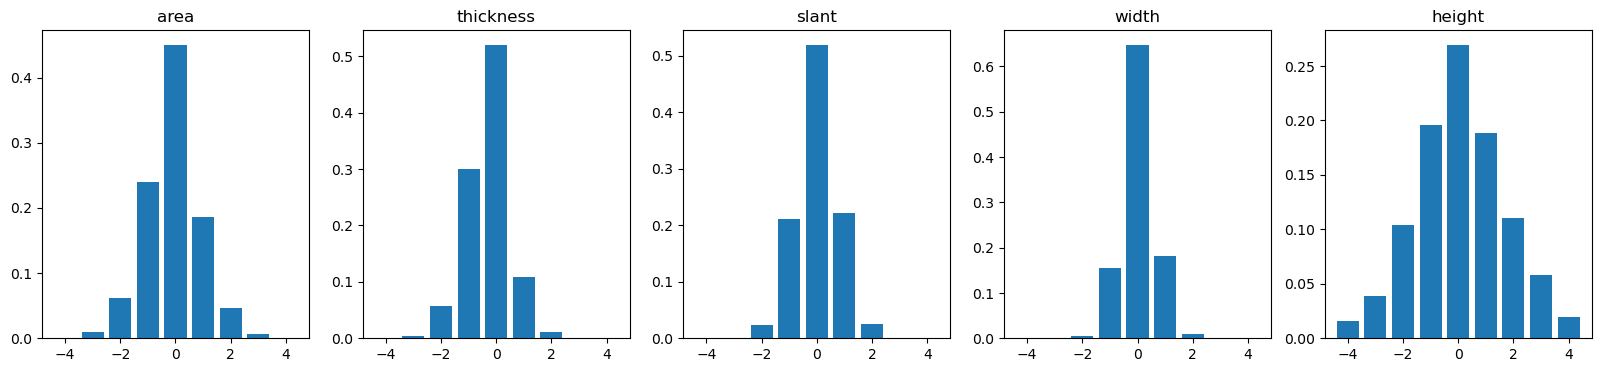

In [235]:
colnames = gap.columns
fig, ax = plt.subplots(1, len(colnames), figsize = (4*len(colnames), 4))
for i, col in enumerate(colnames) :
    ax[i].bar(gap.index, gap[col])
    ax[i].set_title(col)
    
plt.show()

In [236]:
from scipy.stats.contingency import crosstab, chi2_contingency

def C_coef(chi2, n) :
    return chi2/(chi2 +n)

def V_Cramer(chi2, n, k, l) :
    return np.sqrt(chi2 /(n *min(k-1, l-1)))

def get_V_Cramer(y_disc, y_disc_verified) :
    n = y_disc.shape[0]
    k_mod, l_mod = sorted(y_disc.unique()), sorted(y_disc_verified.unique())
    contingency_table = crosstab(y_disc, y_disc_verified, levels = (k_mod, l_mod))
    res = chi2_contingency(contingency_table.count, correction = False)
    chi2, p_value = res.statistic, res.pvalue
    return V_Cramer(chi2, n, len(k_mod), len(l_mod))

In [237]:
colnames = intervals.columns

V = {label:get_V_Cramer(tilde_y_disc[label], tilde_y_disc_verified[label]) for label in colnames}
V

{'area': 0.41992309667324873,
 'thickness': 0.46548672193331725,
 'slant': 0.33176340839607427,
 'width': 0.5634584444330443,
 'height': 0.10182762929215827}

## 3.2. Distance to the good modality

In [238]:
dists = bnl.measure_distance_to_modalities(bnl.dist_to_mod, tilde_y_cont_verif, tilde_y_disc, intervals)
{label:(dists[label] == 0).sum() for label in colnames}

{'area': 4510, 'thickness': 5197, 'slant': 5190, 'width': 6475, 'height': 2693}

In [239]:
dists = bnl.measure_distance_to_modalities(bnl.weighted_dist_to_mod, tilde_y_cont_verif, tilde_y_disc, intervals)
dists

,area,thickness,slant,width,height
0,0.185700,0.520680,0.180636,0.225699,1.637193
1,0.330325,0.696600,0.148605,0.147100,0.147300
2,0.596886,0.605581,0.436973,0.112991,0.751355
3,0.850181,0.427726,0.590695,0.084420,0.835070
4,0.360973,0.478983,0.113173,0.152111,2.335745
...,...,...,...,...,...
9995,0.331678,0.162506,1.381402,0.386522,1.770909
9996,0.064979,0.306984,0.465145,0.148146,0.513271
9997,0.557762,0.139312,0.792863,0.866347,0.729317
9998,1.313149,0.112094,0.192425,0.722113,1.313894


In [240]:
dists.mean(axis = 0)

area         0.719772
thickness    0.598228
slant        0.587324
width        0.437660
height       1.217741
dtype: float64

In [241]:
dists_ext = dists.copy() -0.5
dists_ext[dists_ext < 0] =0
dists_ext.mean(axis = 0)

area         0.331430
thickness    0.221803
slant        0.221843
width        0.111736
height       0.781225
dtype: float64

In [242]:
dists_ext.std(axis = 0)

area         0.502483
thickness    0.368304
slant        0.354218
width        0.231991
height       0.880438
dtype: float64

In [243]:
[dists[label].sort_values().iloc[-3:-2] for label in colnames]

[287    3.603277
 Name: area, dtype: float64,
 6732    2.676663
 Name: thickness, dtype: float64,
 4432    2.82776
 Name: slant, dtype: float64,
 2153    2.409445
 Name: width, dtype: float64,
 200    4.349389
 Name: height, dtype: float64]

## 3.2. MorphoMNIST BN error

# 4. Number prediction

In [210]:
import torch

predicter_path = r"results\Predicter\Predicter_from_z.pt"
Predicter_from_z = torch.load(predicter_path, weights_only=False) 

In [211]:
from libraries.data_loader import load_datas

path = r"datas/brut/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

_, Y_TRAIN, _, Y_VAL = load_datas(path, keys)

In [212]:
latent_train_path = r"datas\brut\z_act_mix_train.csv"
z_act_mix_train = pd.read_csv(latent_train_path)

train_loss, train_acc =  Predicter_from_z(torch.from_numpy(np.array(z_act_mix_train).astype(np.float32)), Y_TRAIN)
train_loss.detach()/z_act_mix_train.shape[0], train_acc/z_act_mix_train.shape[0]

(tensor(0.0375), 0.9959)

In [213]:
test_loss, test_acc =  Predicter_from_z(torch.from_numpy(np.array(z_act_mix).astype(np.float32)), Y_VAL)
test_loss.detach()/z_act_mix.shape[0], test_acc/z_act_mix.shape[0]

(tensor(0.0971), 0.9868)

## 4.2. Verify number with the predicter

In [244]:
tilde_y_number = tilde_y_disc["number"]
test_loss, test_acc =  Predicter_from_z(torch.from_numpy(np.array(tilde_z_act_mix.fillna(0)).astype(np.float32)), tilde_y_number)
test_loss.detach()/tilde_z_act_mix.shape[0], test_acc/z_act_mix.shape[0]

(tensor(4.3117), 0.6187)

In [215]:
tilde_y_number_verified = Predicter_from_z.pred(torch.from_numpy(np.array(tilde_z_act_mix.fillna(0)).astype(np.float32)))
tilde_y_number_verified

array([1, 0, 2, ..., 7, 0, 0], dtype=int64)

In [132]:
tilde_y_number.index = np.arange(tilde_y_number.shape[0])
tilde_y_number

0       4
1       4
2       3
3       1
4       5
       ..
9995    2
9996    1
9997    0
9998    4
9999    3
Name: number, Length: 10000, dtype: int64

In [133]:
V["number"] = get_V_Cramer(tilde_y_number, pd.Series(tilde_y_number_verified))
V

{'area': 0.305211277033693,
 'thickness': 0.37309463595174847,
 'slant': 0.25275424800048607,
 'width': 0.4645530503773133,
 'height': 0.09207589288794478,
 'number': 0.6013534603072339}

In [134]:
tilde_y_disc_verified["number"] = tilde_y_number
tilde_y_disc_verified.head(5)

,area,thickness,slant,width,height,number
0,5,8,7,3,2,4
1,5,6,0,5,3,4
2,8,5,3,6,6,3
3,1,5,6,0,7,1
4,4,3,5,4,6,5


In [135]:
tilde_y_disc_verif_path = r"datas\MorphoMNIST\10_10\rbn_99\tilde_y_disc_verif.csv"
tilde_y_disc_verified.to_csv(tilde_y_disc_verif_path)

# 5. Divergences

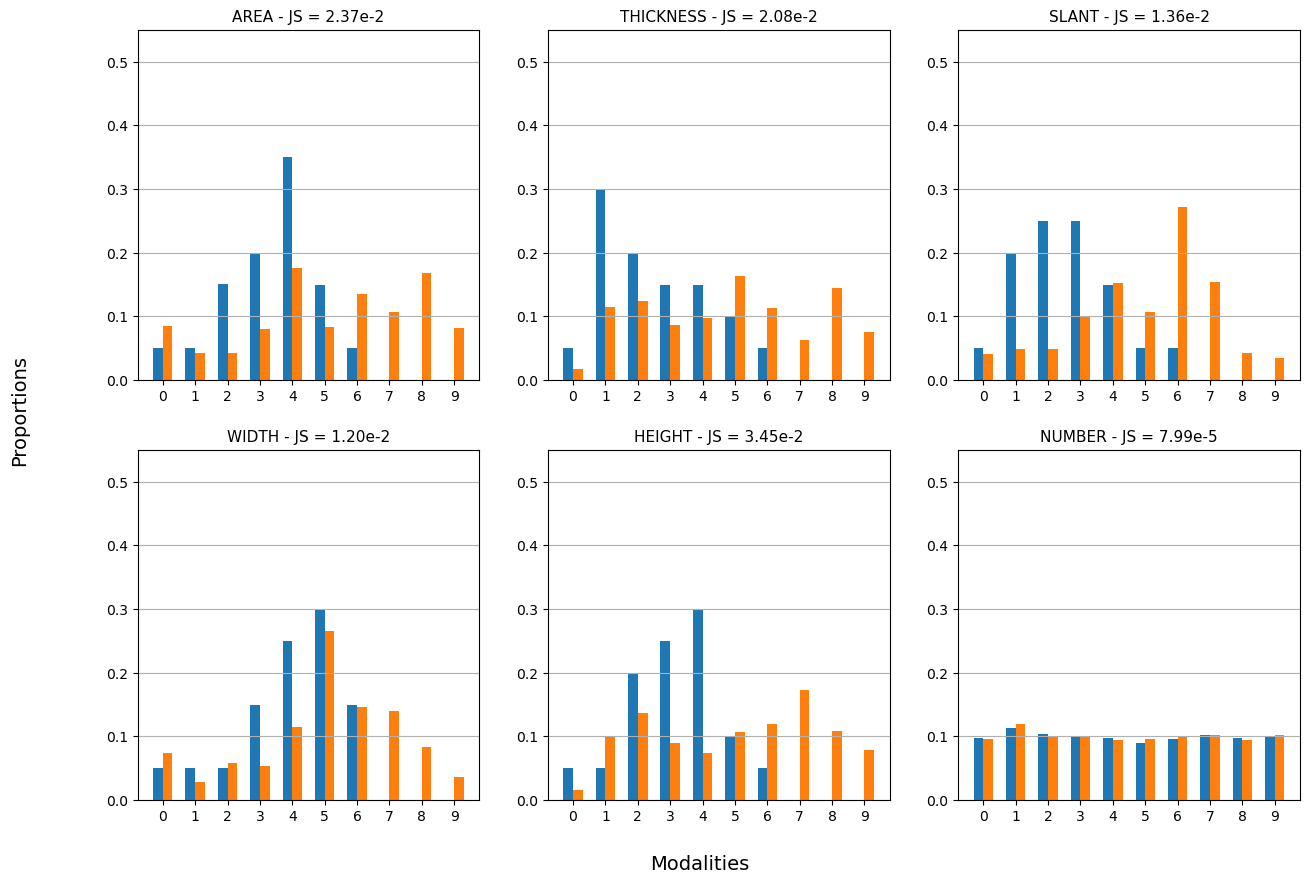

In [136]:
import libraries.metrics as ms

w, h = 3, 2
fig = plt.figure(figsize = (5*w, 5*h))

for i, col in enumerate(y_disc.columns) :
    plt.subplot(h, w, i +1)
    nb_mod = y_disc[col].unique()
    eff = len(y_disc)

    curr_Y_real = y_disc[[col]].value_counts().reset_index()
    curr_Y_gen = tilde_y_disc_verified[[col]].value_counts().reset_index()
    curr_Y_real.columns = [curr_Y_real.columns[0], "count"]
    curr_Y_gen.columns = [curr_Y_gen.columns[0], "count"]
    JS = ms.Jensen_Shannon(curr_Y_real["count"]/eff, curr_Y_gen["count"]/eff)

    width = 0.15
    plt.bar(curr_Y_real[col] -width, curr_Y_real["count"]/eff, width = 2*width)
    plt.bar(curr_Y_gen[col] +width, curr_Y_gen["count"]/eff, width = 2*width)

    plt.title(f'{col.upper()} - JS = {ms.format_pow10(JS)}', fontsize = 11)
    plt.ylim(0, 0.55)
    plt.grid(axis = "y")
    
    modality = sorted(curr_Y_gen[col].unique())
    
    
    plt.xticks(modality)

fig.text(0.5, 0.04, 'Modalities', ha='center', fontsize = 14)
fig.text(0.04, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)

plt.show()
# fig.savefig(os.path.join(path, "Global dicrete distrib.png"))

In [137]:
colnames = list(y_disc.columns)

In [138]:
n = y_disc.shape[0]

Y_DISC = y_disc.copy() 
TILDE_Y_DISC = tilde_y_disc.copy() 
TILDE_Y_DISC_verified = tilde_y_disc_verified.copy() 

Y_DISC["E"] = 1
Y_DISC = Y_DISC.groupby(by = colnames).count()/n # .reset_index().sort_values(by = colnames)

TILDE_Y_DISC["E"] = 1
TILDE_Y_DISC = TILDE_Y_DISC.groupby(by = colnames).count()/n # .reset_index().sort_values(by = colnames)

TILDE_Y_DISC_verified["E"] = 1
TILDE_Y_DISC_verified = TILDE_Y_DISC_verified.groupby(by = colnames).count()/n # .reset_index().sort_values(by = colnames)

Y_DISC.head(5), Y_DISC.shape

(                                               E
 area thickness slant width height number        
 0    0         0     2     3      4       0.0001
                            6      3       0.0001
                      3     3      7       0.0001
                            6      9       0.0001
                1     0     4      1       0.0002,
 (4942, 1))

In [139]:
%autoreload 2
import libraries.metrics as ms

In [140]:
P = Y_DISC.copy()
Q = TILDE_Y_DISC.copy()
Q2 = TILDE_Y_DISC_verified.copy()

ms.Jensen_Shannon(Y_DISC, TILDE_Y_DISC), ms.Jensen_Shannon(Y_DISC, TILDE_Y_DISC_verified)

(E    0.659074
 dtype: float64,
 E    0.667702
 dtype: float64)

(E    0.171217
 dtype: float64,
 E    0.226814
 dtype: float64)

E
area thickness slant width height number          
0    0         0     2     2      4       0.284253
                                  7      -0.117526
                           4      3      -0.117526
                                  9      -0.117526
                     3     0      2       0.882042
...                                            ...
4    4         4     3     2      7      -0.117526
                                  8      -0.117526
                     4     0      2      -0.117526
                                  4      -0.117526
                           2      2      -0.117526

[2506 rows x 1 columns]

In [880]:
idx = sum_on_M[sum_on_M["E"] >= sum_on_M["E"].max()].index
idx

MultiIndex([(0, 1, 2, 0, 3, 1),
            (0, 2, 2, 0, 3, 1)],
           names=['area', 'thickness', 'slant', 'width', 'height', 'number'])

In [881]:
P.loc[idx]

E
area thickness slant width height number       
0    1         2     0     3      1       0.008
     2         2     0     3      1       0.008

In [888]:
(0.008*np.log(0.008/M_hyp)).sum()

E    121.918475
dtype: float64

In [ ]:
P_index = list(set(Y_DISC.index) -set(TILDE_Y_DISC.index))
test = pd.DataFrame(np.array([1e-16]*len()))

In [ ]:
P

In [ ]:
Y_D2, T_Y_D_v = syncro_PQ(Y_DISC.copy(), TILDE_Y_DISC_verified.copy())
Y_D2.shape, T_Y_D_v.shape

((3960, 1), (3960, 1))

In [764]:
M = (Y_D + T_Y_D)/2
M2 = (Y_D2 + T_Y_D_v)/2
M.sum(), M2.sum()

(E    1.0
 dtype: float64,
 E    1.0
 dtype: float64)

In [765]:
ms.Jensen_Shannon(Y_D, T_Y_D), ms.Jensen_Shannon(Y_D2, T_Y_D_v)

(E    0.160478
 dtype: float64,
 E    0.2162
 dtype: float64)

In [ ]:
def D_KL(P, Q) : 
    return (P*np.log(P/Q)).sum()

def Jensen_Shannon(P, Q) :
    M = (P+Q)/2
    return (D_KL(P, M) +D_KL(Q, M)) /2 

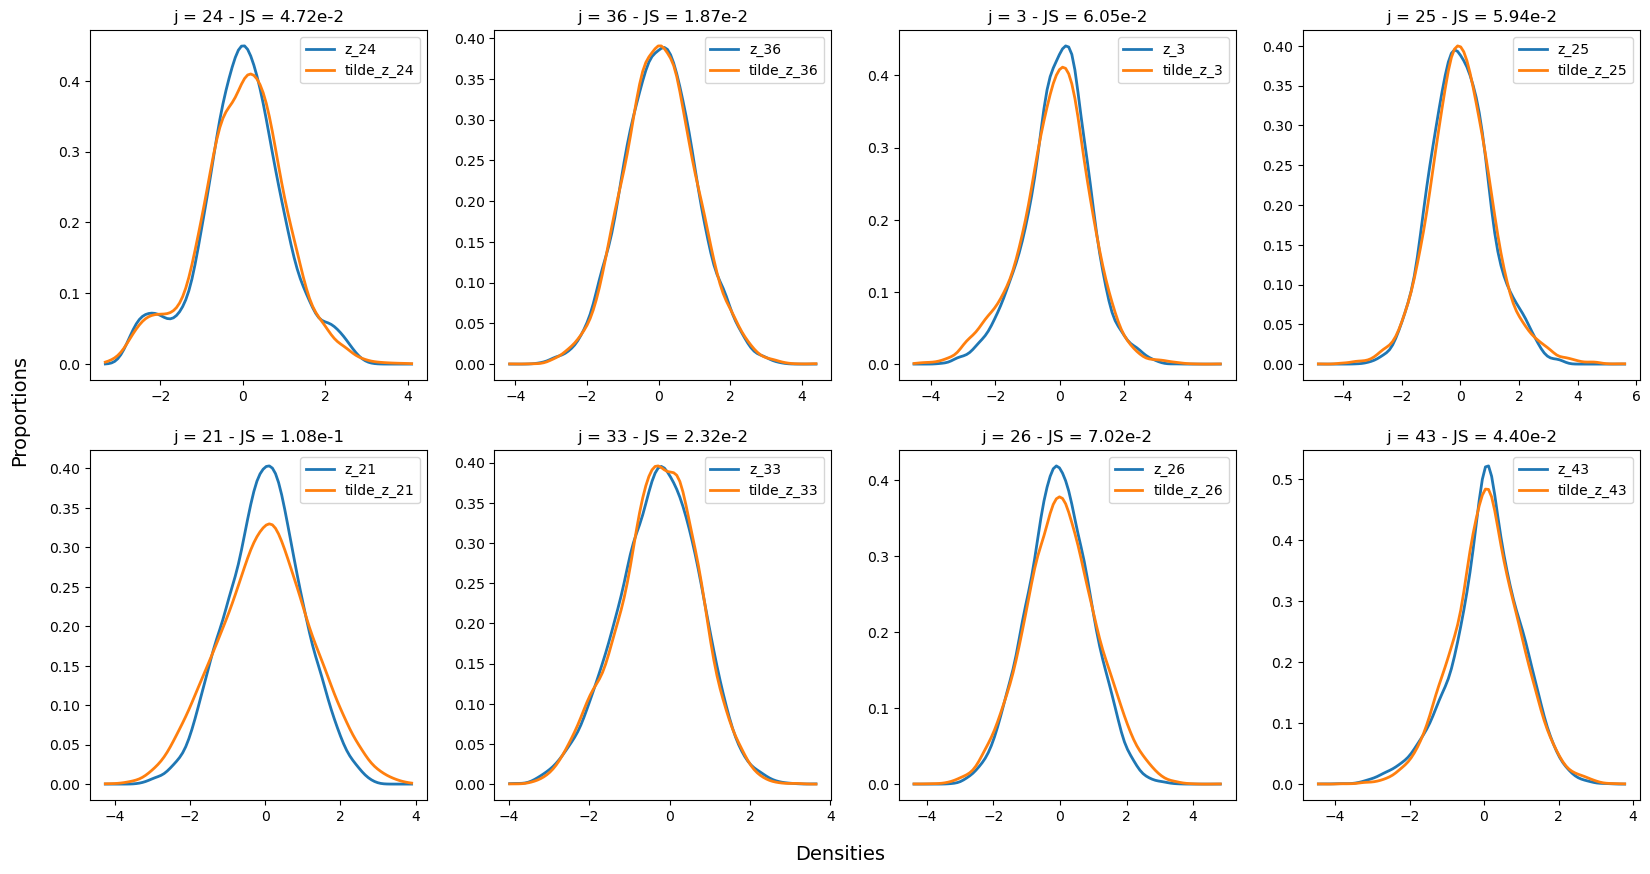

In [751]:
from scipy.stats import gaussian_kde
from scipy.spatial.distance import jensenshannon

z_act_mix.columns = tilde_z_act_mix.columns


w, h = 4, 2
fig = plt.figure(figsize = (5*w, 5*h))

for i, col in enumerate(z_act_mix.columns[:8]) :

    curr_x_real = z_act_mix[col].copy()
    curr_x_gen = tilde_z_act_mix[col].copy().fillna(0.0)
    
    plt.subplot(h, w, i +1)
    X, hat_X = curr_x_real, curr_x_gen
    kde_real = gaussian_kde(X)
    kde_gen = gaussian_kde(hat_X)
    xmin = min(X.min(), hat_X.min())
    xmax = max(X.max(), hat_X.max())
    
    grid = np.linspace(xmin, xmax, 100) # grids = [np.linspace(xmin, xmax, n) for n in [200, 500, 1000, 2000, 5000]]

    p_X = kde_real(grid)
    p_hat_X = kde_gen(grid)

    JS = np.round(jensenshannon(p_X, p_hat_X), 5)
    plt.plot(grid, p_X, linewidth = 2)
    plt.plot(grid, p_hat_X, linewidth = 2)
    plt.title(f'j = {col} - JS = {ms.format_pow10(JS)}')
    plt.legend([f"z_{col}", f"tilde_z_{col}"])


fig.text(0.5, 0.05, f'Densities', ha='center', fontsize = 14)
fig.text(0.085, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)
plt.show()
# fig.savefig(f"Countinuous distrib - {col.upper()} = {m} and {curr_col_2.upper()} = {m2}.pdf")